In [2]:
import sys
sys.path.append('../src/')
from xpcs import *
from plotting import *
from autocorrelations import *
import cv2
from scipy.special import erfinv
import pyopencl as cl
from pathlib import Path
import matplotlib.cm as cm
import json
import matplotlib.ticker as ticker
#from cmcrameri import cm
import matplotlib as mpl

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap

from scipy.interpolate import interp1d
from scipy.signal import detrend


%matplotlib inline


In [3]:
### Figure Settings ###

plt.rcParams['font.sans-serif'] = ['Helvetica']

legend_ax_font = 12
ax_label_font = 16
ax_title_font = 18

minor_tick_length = 6
major_tick_length = 9
minor_tick_width = 0.75
major_tick_width = 1.0

fig_size = (8,5)

nps_custom = LinearSegmentedColormap.from_list(
  'nps_custom', [
    (0.00, '#000000'),
    (0.07, '#342c7a'), #0.12
    (0.20, '#a43479'), #25
    (0.55, '#d74444'),
    (0.78, '#f3de80'),
    (1.00, '#ffffff'),
], N=256
)

In [4]:
Scan = 219

In [ ]:
# Define the path to the configuration file
config_path = Path("../configs/config_NPS_example.json")

# Open and load the JSON configuration file
with open(config_path, "r") as file:
    config = json.load(file)
    #json_str = json.loads(jsonString, strict=False)

### Output Directory ###
figure_path = config_path.parent.parent / config.get("Figures")
figure_path.mkdir(parents=True, exist_ok=True)

base_path = Path(config.get("Base")) 
results_path = Path(config.get("Results"))
file = base_path / Path(config.get(f"{Scan}")) / results_path / Path(config.get(f"{Scan}_results"))

with h5py.File(file, 'r') as DATA:
    g2s = DATA['XPCS/G2_Results'][:]
    g2_errs = DATA['XPCS/G2_error'][:]
    delays = DATA['XPCS/delays'][:]
    dQ = DATA['XPCS/dQ'][:]
    As = DATA['XPCS/As'][:][0]
    aas = DATA['XPCS/aas'][:][0]

    # Cs = DATA['XPCS/Cs'][:]
    taus = DATA['XPCS/taus'][:]
    betas = DATA['XPCS/betas'][:]
    taus_err = DATA['XPCS/taus_err'][:]
    betas_err = DATA['XPCS/betas_err'][:]
    
    #TwoTime
    TwoTime = DATA['XPCS/TwoTime'][:]
    #print(TwoTime.shape)
    TwoTime_extent = DATA['XPCS/TwoTime_extent'][:]

# After computing C (the covariance version)
##d = np.sqrt(np.diag(TwoTime))
#TwoTime_norm = TwoTime / np.outer(d, d)






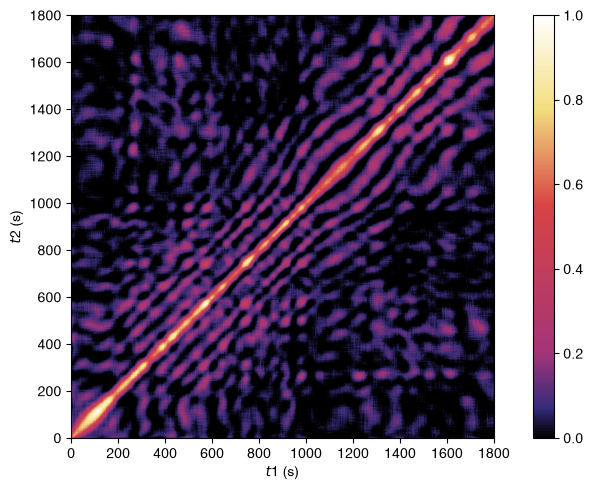

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=fig_size)
im = ax.imshow(TwoTime, cmap=nps_custom, origin="lower",extent=TwoTime_extent,vmin=0,vmax=1)
ax.set_xlabel("$t$1 (s)")
ax.set_ylabel("$t$2 (s)")
fig.colorbar(im, ax=ax)
plt.tight_layout()



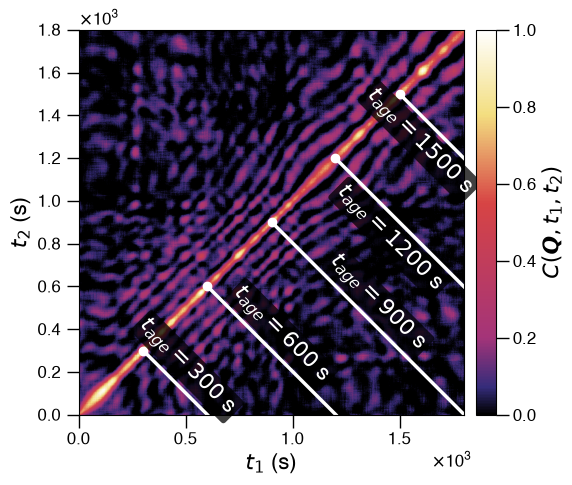

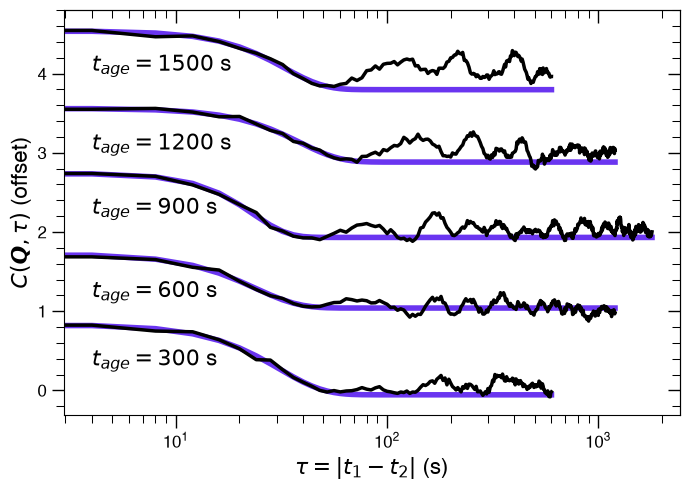

In [7]:
import matplotlib.pyplot as plt

POPT = []
PCOV = []

# t1_start in seconds; None uses the matrix center
t1_starts = np.array([300,600,900,1200,1500])  # e.g. 50.0

offsets = [-22.5, -22.5, -22.5, 22.5, 22.5]  # points in display units; adjust as needed

# Optional: show the cut on the two-time map
fig1, ax1 = plt.subplots(figsize=fig_size)
fig2, ax2 = plt.subplots(figsize=(7,5))

im = ax1.imshow(TwoTime, cmap=nps_custom, origin="lower", extent=TwoTime_extent,vmin = 0,vmax = 1)

cuts = []
for i,t1 in enumerate(t1_starts):
    cut = semi_antidiagonal_linecut(TwoTime, extent=TwoTime_extent, t1_start=t1)
    cuts.append(cut)
    ax1.plot(cut["t2"], cut["t1"], color="white", lw=2.5)
    ax1.plot(cut["t2"][0], cut["t1"][0], "o", color="white", ms=6)

    mask = cut["delta_tau"] < 60

    if t1 == 600:
        mask = cut["delta_tau"] < 50

    popt, pcov = curve_fit(g2_exp_c, cut["delta_tau"][mask], cut["values"][mask], p0=[0.75,40,2.2,0.00])#,bounds=([0.1,0,0,0],[1,200,10,1]))
    POPT.append(popt)
    PCOV.append(pcov)

    norm_data = (cut["values"]-popt[-1])/popt[0]
    norm_fit = (g2_exp_c(cut["delta_tau"], *popt)-popt[-1])/popt[0]

    ax2.semilogx(cut["delta_tau"], cut["values"]+i, "k-", lw=2.5,zorder=2)
    ax2.semilogx(cut["delta_tau"], g2_exp_c(cut["delta_tau"], *popt)+i, '#6a35f0', lw=4,zorder=1)


    # Place a text label parallel and just above each white line on ax1
    # Compute the midpoint index for the cut
    npts = len(cut["t1"])
    mid_idx = npts // 2 if npts > 1 else 0
    x0, y0 = cut["t2"][mid_idx], cut["t1"][mid_idx]

    # Compute the direction angle of the line at the midpoint (in data coords)
    # Use points before and after mid_idx to get the direction vector
    if npts >= 3:
        if mid_idx == 0:
            # Too short, just use next point
            dx = cut["t2"][1] - cut["t2"][0]
            dy = cut["t1"][1] - cut["t1"][0]
        elif mid_idx == npts - 1:
            dx = cut["t2"][-1] - cut["t2"][-2]
            dy = cut["t1"][-1] - cut["t1"][-2]
        else:
            dx = cut["t2"][mid_idx+1] - cut["t2"][mid_idx-1]
            dy = cut["t1"][mid_idx+1] - cut["t1"][mid_idx-1]
    else:
        dx = cut["t2"][-1] - cut["t2"][0]
        dy = cut["t1"][-1] - cut["t1"][0]

    angle = np.degrees(np.arctan2(dy, dx))

    # Use an offset perpendicular to the line direction (for "just above" effect)
    offset = offsets[i]  # points in display units; adjust as needed
    # Perpendicular angle
    perp_angle_rad = np.arctan2(-dx, dy)
    dx_pix = offset * np.cos(perp_angle_rad)
    dy_pix = offset * np.sin(perp_angle_rad)
    # Convert midpoint data coords to display (pixel) coords, apply offset, then back to data
    transData = ax1.transData
    trans = transData.transform
    invtrans = transData.inverted().transform
    mid_disp = trans((x0, y0))
    label_disp = (mid_disp[0] + dx_pix, mid_disp[1] + dy_pix)
    x_label, y_label = invtrans(label_disp)

    line_label = "$t_{age}=$"+f"${t1:.0f}$ s"

    if t1 == 300:
        x_label -= -10
    if t1 == 1500:
        x_label -= 10
    ax1.text(x_label, y_label, line_label, color="white", fontsize=legend_ax_font+4, rotation=angle,
             rotation_mode="anchor", ha="center", va="center", bbox=dict(facecolor='black', alpha=0.75, edgecolor='none', boxstyle='round,pad=0.15'))

# t1 labels on linecut plot: same x, black text under each curve
label_x = max(np.min(c["delta_tau"][c["delta_tau"] > 0]) for c in cuts)
label_dy = 0.1
for i, (t1, cut) in enumerate(zip(t1_starts, cuts)):
    norm_position = (cut["values"]-POPT[i][-1])/POPT[i][0]
    y = np.interp(label_x, cut["delta_tau"], cut["values"]+i - label_dy)
    ax2.text(
        label_x, y-0.2, "$t_{age}$"+f"$={t1:.0f}$ s",
        color="k", fontsize=legend_ax_font+4, ha="left", va="top",
    )

ax1.set_xlabel(r"$t_1$ (s)",fontsize=ax_label_font)
ax1.set_ylabel(r"$t_2$ (s)",fontsize=ax_label_font)

ax1.xaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
ax1.xaxis.get_offset_text().set_fontsize(legend_ax_font)  # Adjust font size if needed
ax1.xaxis.get_offset_text().set_position((1.02, 0))  # Move offset label slightly

ax1.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
ax1.yaxis.get_offset_text().set_fontsize(legend_ax_font)
ax1.yaxis.get_offset_text().set_position((0, 1.02))  # Move offset label slightly

ax1.ticklabel_format(axis='both', style='sci', scilimits=(0, 0))  # Force scientific notation

ax1.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
ax1.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font)

cbar = fig1.colorbar(
    im,
    ax=ax1,
    pad=0.02,
    fraction=0.035,
    shrink=1.0,
)
cbar.set_label(r'$C(\boldsymbol{Q},t_1,t_2)$', fontsize=ax_label_font)
cbar.ax.tick_params(
            which="major", length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font
        )
cbar.ax.tick_params(
            which="minor", length=minor_tick_length, width=minor_tick_width, labelsize=legend_ax_font
        )

# Linecut in a separate figure (x = lag along the anti-diagonal direction)
ax2.set_xlabel(r"$\tau = |t_1 - t_2|$ (s)",fontsize=ax_label_font)
ax2.set_ylabel(r'$C(\boldsymbol{Q},\tau)$ (offset)',fontsize=ax_label_font)

ax2.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
ax2.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font)

axt2, axr2 = asymmetric_ticks(ax2,major_len=major_tick_length, minor_len=minor_tick_length, major_w=major_tick_width, minor_w=minor_tick_width, labelsize=legend_ax_font)

plt.tight_layout()
plt.show()


fig1.savefig(figure_path / "ttc_219.pdf",format="pdf",dpi=300,bbox_inches="tight",metadata={'Creator': ''})

fig2.savefig(figure_path / "isf_219.pdf",format="pdf",dpi=300,bbox_inches="tight",metadata={'Creator': ''})

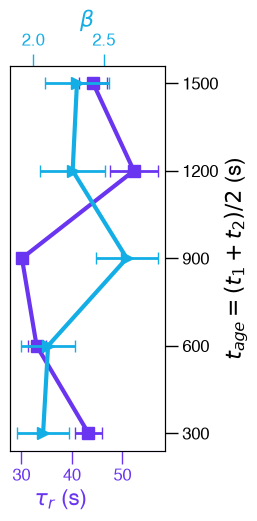

In [8]:
fig,ax = plt.subplots(figsize=(2,5))

tau_color =  '#6a35f0'#        #'#cc5e5e' #'#ce4b5b'
beta_color = '#13aee5' #'#373079' 

y = np.array([300,600,900,1200,1500])
taus = np.array([POPT[i][1] for i in range(len(POPT))])
taus_err = np.array([np.sqrt(PCOV[i][1,1]) for i in range(len(PCOV))])


betas = np.array([POPT[i][2] for i in range(len(POPT))])
betas_err = np.array([np.sqrt(PCOV[i][2, 2]) for i in range(len(PCOV))])

ax2 = ax.twiny()
ax2.plot(betas, y, ">-",markersize=8,color=beta_color,lw=3)
ax2.errorbar(betas,y,xerr=betas_err,fmt="none",color=beta_color,lw=2,ms=10,capsize=4)

ax2.set_xlabel(r"$\beta$", fontsize=ax_label_font)


ax.plot(taus,y,"s-",markersize=8,color=tau_color,lw=3)
ax.errorbar(taus,y,xerr=taus_err,fmt="none",color=tau_color,lw=2,ms=10,capsize=4)
ax.set_xlabel(r"$\tau_r$ (s)",fontsize=ax_label_font,ha='right')
ax.set_ylabel("$t_{age} = (t_1+t_2)/2$ (s)",fontsize=ax_label_font)
ax.yaxis.tick_right()
ax.yaxis.set_label_position("right")

ax2.tick_params(axis='y', colors=beta_color)

ax.set_yticks(y)
ax.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
ax.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font)


ax2.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
ax2.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font)


# bottom: tau
ax.tick_params(axis='x', colors=tau_color)
ax.spines['bottom'].set_color(tau_color)
ax.xaxis.label.set_color(tau_color)

# top: beta
ax2.tick_params(axis='x', colors=beta_color)
#ax2.spines['top'].set_color(beta_color)
ax2.xaxis.label.set_color(beta_color)

fig.savefig(figure_path / "tau_beta_219.pdf",format="pdf",dpi=300,bbox_inches="tight",metadata={'Creator': ''})


In [9]:
print(r"Mean $\tau_r$ =", np.mean(taus))
print(r"Std. $\tau_r$ =", np.std(taus)/np.sqrt(len(taus)))
print(r"Mean $\beta$ =", np.mean(betas))
print(r"Std. $\beta$ =", np.std(betas)/np.sqrt(len(betas)))

Mean $\tau_r$ = 40.55590714387687
Std. $\tau_r$ = 3.599426184667594
Mean $\beta$ = 2.2852436474540356
Std. $\beta$ = 0.09428946098750364


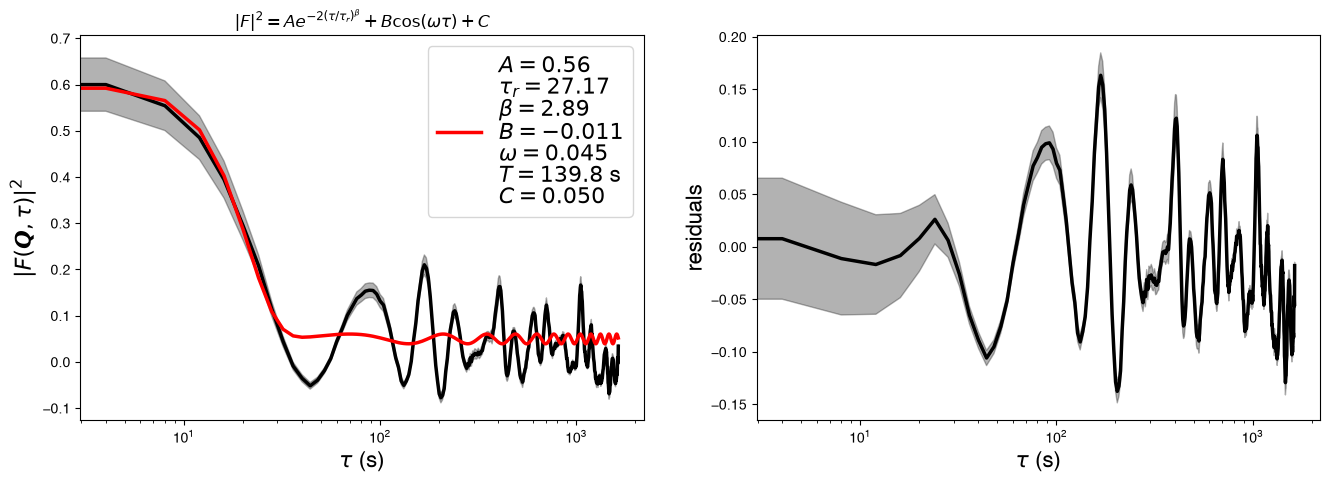

A=0.5570, tau_r=27.1679, beta=2.8914, B=-0.0105, omega=0.04495, T=139.77 s, C=0.0498


In [10]:
def parabola(x, a, b, c):
    return a * (np.log10(x) - np.log10(b)) ** 2 + c


def isf_glass_shear(t, A, tt, b, B, omega, C):
    """Homodyne |F|^2 = A exp[-2(τ/τr)^β] + B cos(ωτ) + C.

    Glass relaxation (stretched exp) + deterministic shear-flow oscillation.
    """
    t = np.asarray(t, dtype=float)
    return A * np.exp(-2.0 * (t / tt) ** b) + B * np.cos(omega * t) + C


### User Input ###
t1 = 800

# Create a window of t1s to average over
window = 10
tau_max_fit = 300  # need enough lag to constrain ω

# Define the t1s to average over
t1s = np.arange(TwoTime_extent[0], TwoTime_extent[1], 2)

begin = np.where(t1s == t1)[0][0] - window
end = np.where(t1s == t1)[0][0] + window

cut_list, tau_list = [], []
if window > 0:
    for t1_w in t1s[begin:end]:
        cut_w = semi_antidiagonal_linecut(TwoTime, extent=TwoTime_extent, t1_start=t1_w)
        cut_list.append(cut_w["values"])
        tau_list.append(cut_w["delta_tau"])
    cut, cut_err, tau = average_linecuts(cut_list, tau_list)
else:
    cut_center = semi_antidiagonal_linecut(TwoTime, extent=TwoTime_extent, t1_start=t1)
    cut = cut_center["values"]
    tau = cut_center["delta_tau"]
    cut_err = np.zeros_like(cut)
    cut_list = [cut]
    tau_list = [tau]

mask = tau < tau_max_fit

# |F|^2 = A exp[-2(τ/τr)^β] + B cos(ωτ) + C
omega0 = 2 * np.pi / 141.0  # ~period from residual oscillations
p0 = [0.7, 40.0, 2.0, 0.05, omega0, 0.05]
bounds = (
    [0.0, 1.0, 0.2, -1.0, 0.0, -0.5],
    [2.0, 500.0, 4.0, 1.0, 1.0, 0.5],
)
popt, pcov = curve_fit(
    isf_glass_shear, tau[mask], cut[mask], p0=p0, bounds=bounds, maxfev=50000
)
A, tt, beta, B, omega, C = popt
sigma_A = np.sqrt(pcov[0, 0])
period = 2 * np.pi / omega if omega > 0 else np.nan

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

isf_cut = cut
isf_fit = isf_glass_shear(tau, *popt)
resid = isf_cut - isf_fit

# error from cut measurement
err_from_cut = cut_err
# error from amplitude (propagate contrast uncertainty into |F|^2 scale)
err_from_A = np.abs(isf_cut) * (sigma_A / A) if A != 0 else np.zeros_like(isf_cut)
isf_err = np.sqrt(err_from_cut**2 + err_from_A**2)

ax[0].semilogx(tau, isf_cut, "k-", lw=2.5)
ax[0].fill_between(tau, isf_cut - isf_err, isf_cut + isf_err, color="k", alpha=0.3)

ax[0].semilogx(
    tau,
    isf_fit,
    "r-",
    lw=2.5,
    label=(
        r"$A={:.2f}$" "\n"
        r"$\tau_r={:.2f}$" "\n"
        r"$\beta={:.2f}$" "\n"
        r"$B={:.3f}$" "\n"
        r"$\omega={:.3f}$" "\n"
        r"$T={:.1f}$ s" "\n"
        r"$C={:.3f}$"
    ).format(A, tt, beta, B, omega, period, C),
)
ax[1].semilogx(tau, resid, "k-", lw=2.5)
ax[1].fill_between(tau, resid - isf_err, resid + isf_err, color="k", alpha=0.3)

ax[0].set_xlabel(r"$\tau$ (s)", fontsize=ax_label_font)
ax[0].set_ylabel(r"$|F(\boldsymbol{Q},\tau)|^2$", fontsize=ax_label_font)
ax[0].legend(fontsize=ax_label_font)
ax[0].set_title(
    r"$|F|^2 = A e^{-2(\tau/\tau_r)^\beta} + B\cos(\omega\tau) + C$"
)
ax[1].set_xlabel(r"$\tau$ (s)", fontsize=ax_label_font)
ax[1].set_ylabel(r"residuals", fontsize=ax_label_font)

plt.show()

print(
    f"A={A:.4f}, tau_r={tt:.4f}, beta={beta:.4f}, "
    f"B={B:.4f}, omega={omega:.5f}, T={period:.2f} s, C={C:.4f}"
)


period from peak spacing Δτ = 105.706 ± 2.158 s


/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_67487/2170531101.py:85: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


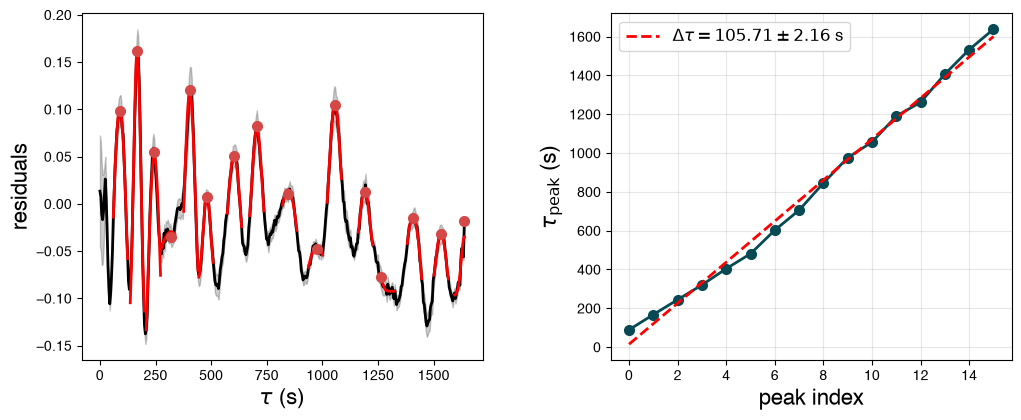

peak index, τ_peak:
   0  89.085 s
   1  167.417 s
   2  244.191 s
   3  320.095 s
   4  403.860 s
   5  480.970 s
   6  602.493 s
   7  705.499 s
   8  845.255 s
   9  976.027 s
  10  1056.198 s
  11  1189.903 s
  12  1261.402 s
  13  1406.901 s
  14  1532.681 s
  15  1637.820 s


In [11]:
# Fit peaks in the residual and plot τ_peak vs peak index
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

# search window for oscillatory residual structure (adjust as needed)
tau_lo, tau_hi = 40.0, 1780.0
search = (tau > tau_lo) & (tau < tau_hi) & np.isfinite(resid)
tau_s = np.asarray(tau[search], dtype=float)
resid_s = np.asarray(resid[search], dtype=float)

# find local maxima (prominence relative to residual scale)
prom = 0.15 * np.nanstd(resid_s)
peak_idx, props = find_peaks(resid_s, prominence=max(prom, 1e-4), distance=5)

def _gauss(x, A, x0, sigma, c):
    return A * np.exp(-0.5 * ((x - x0) / sigma) ** 2) + c

peak_locations = []
peak_amps = []
peak_indices = []
fit_curves = []  # (tau_local, y_fit) for overlay

for n, i0 in enumerate(peak_idx):
    # local window around each peak (in sample index)
    half = 8
    i1 = max(0, i0 - half)
    i2 = min(len(tau_s), i0 + half + 1)
    x = tau_s[i1:i2]
    y = resid_s[i1:i2]
    if x.size < 4:
        continue
    A0 = float(y.max() - np.median(y))
    x0 = float(tau_s[i0])
    sig0 = max(0.05 * x0, float(np.ptp(x)) / 6.0)
    c0 = float(np.median(y))
    try:
        popt_pk, _ = curve_fit(
            _gauss, x, y, p0=[A0, x0, sig0, c0],
            bounds=([0, x.min(), 1e-6, -np.inf], [np.inf, x.max(), np.ptp(x) * 2, np.inf]),
            maxfev=10000,
        )
        peak_indices.append(n)
        peak_locations.append(popt_pk[1])
        peak_amps.append(popt_pk[0])
        xx = np.linspace(x.min(), x.max(), 80)
        fit_curves.append((xx, _gauss(xx, *popt_pk)))
    except Exception:
        # fall back to find_peaks sample location
        peak_indices.append(n)
        peak_locations.append(x0)
        peak_amps.append(float(resid_s[i0]))

peak_indices = np.asarray(peak_indices, dtype=int)
peak_locations = np.asarray(peak_locations, dtype=float)
peak_amps = np.asarray(peak_amps, dtype=float)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5),gridspec_kw={'wspace': 0.32})

ax[0].plot(tau, resid, "k-", lw=2)
ax[0].fill_between(tau, resid - isf_err, resid + isf_err, color="k", alpha=0.2)
for xx, yy in fit_curves:
    ax[0].plot(xx, yy, "r-", lw=2)
ax[0].plot(peak_locations, peak_amps * 0 + np.interp(peak_locations, tau_s, resid_s),
           "o", color="#d54848", ms=7, zorder=5)
ax[0].set_xlabel(r"$\tau$ (s)", fontsize=ax_label_font)
ax[0].set_ylabel("residuals", fontsize=ax_label_font)
#ax[0].set_title("residual peaks")

ax[1].plot(peak_indices, peak_locations, "o-", color="#074a54", ms=7, lw=2)
if peak_indices.size >= 2:
    # linear fit: τ_n = τ0 + n * Δτ
    coeff, cov = np.polyfit(peak_indices, peak_locations, 1, cov=True)
    dtau = coeff[0]
    dtau_err = float(np.sqrt(cov[0, 0]))
    n_fit = np.linspace(peak_indices.min(), peak_indices.max(), 50)
    ax[1].plot(n_fit, np.polyval(coeff, n_fit), "r--", lw=2,
               label=rf"$\Delta\tau={dtau:.2f}\pm{dtau_err:.2f}$ s")
    ax[1].legend(fontsize=legend_ax_font)
    print(f"period from peak spacing Δτ = {dtau:.3f} ± {dtau_err:.3f} s")
ax[1].set_xlabel("peak index", fontsize=ax_label_font)
ax[1].set_ylabel(r"$\tau_{{\mathrm{{peak}}}}$ (s)", fontsize=ax_label_font)
#ax[1].set_title(r"peak location vs index")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("peak index, τ_peak:")
for n, tpk in zip(peak_indices, peak_locations):
    print(f"  {n:2d}  {tpk:.3f} s")


#fig.savefig(
#    figure_path / "residual_peaks.pdf",
#    format="pdf", dpi=300, bbox_inches="tight", metadata={"Creator": ""},
#)


<>:131: SyntaxWarning: invalid escape sequence '\,'
<>:131: SyntaxWarning: invalid escape sequence '\,'
/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_67487/3733101797.py:131: SyntaxWarning: invalid escape sequence '\,'
  #ax2.axvline(popt1[1], color=tau1_color, ls='--', lw=3, label=rf'$\tau={popt1[1]:.0f}\,s$')
/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_67487/3733101797.py:160: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend(frameon=False,fontsize=ax_label_font)


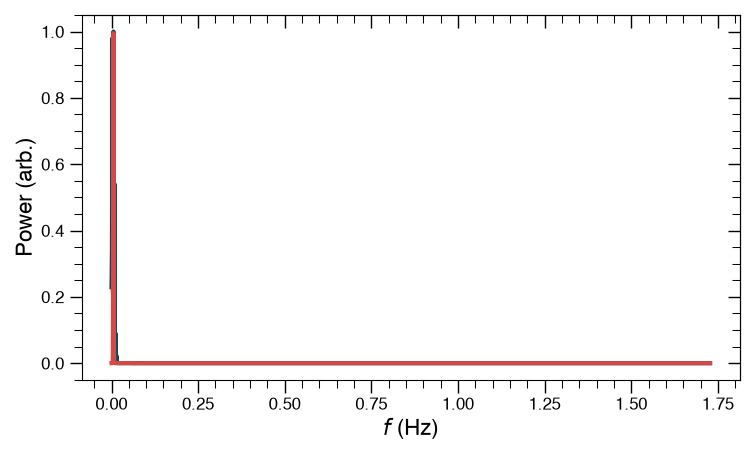

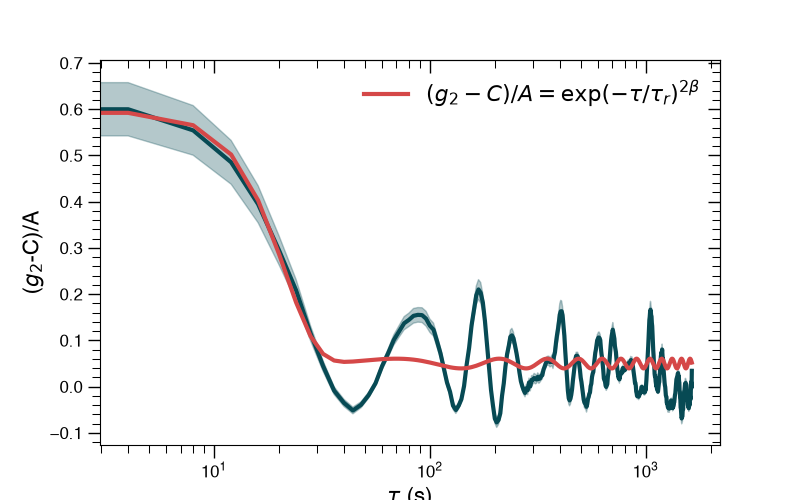

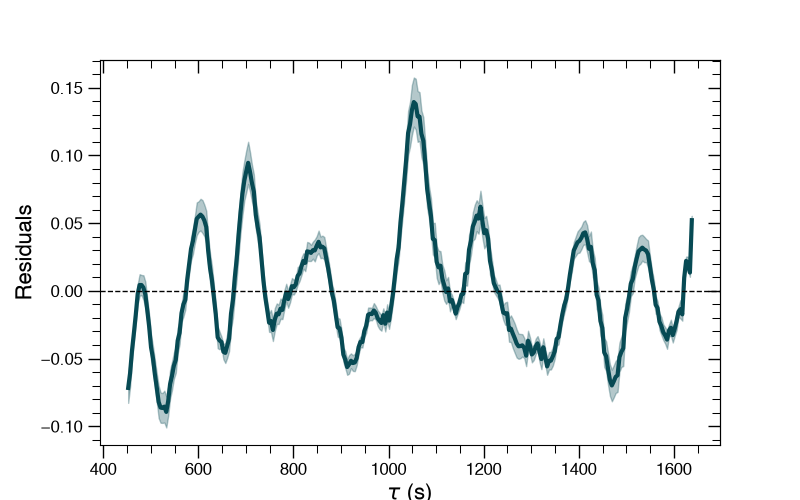

In [12]:
%matplotlib widget

t1s = np.arange(TwoTime_extent[0],TwoTime_extent[1],2)


color = '#074a54'

fit_color = '#d54848'
freq_color = '#373079' 
freq_color = color



# --- FFT on uniform linear tau grid ---
# Trim noisy tail
#mask = tau > 1  # skip very short lags if noisy
#tau_trim = tau[mask]
#resid_trim = resid[mask]

#mask = tau_no_dc > 1  # skip very short lags if noisy
mask = (tau > tau_max_fit*1.5) & (tau < 1800)   # the oscillatory region, explicit bounds
tau_trim = tau[mask]
resid_trim = detrend(resid[mask])
isf_err_trim = isf_err[mask]

freqs, power = fft_analysis(tau_trim, resid_trim)

#freqs = np.fft.rfftfreq(len(resid_windowed), d=d_log_tau)
#power = np.abs(np.fft.rfft(resid_windowed))**2

#freqs = np.fft.rfftfreq(len(resid_uniform), d=d_log_tau)
#power = np.abs(np.fft.rfft(resid_uniform))**2

peak_idx = np.argmax(power)



#low_pass_filter
power_no_dc = power.copy()
#power_no_dc[:np.where(freqs < 1/np.log10(4))[0][0]] = 0

#Fit Max Power

def gaussian_no_bl(x, amp, x0, sigma):
    return amp * np.exp(-(x - x0)**2 / (2 * sigma**2))
# Fit window around peak
window_half = 5  # adjust based on peak width
lo = max(1, peak_idx - window_half)
hi = min(len(freqs), peak_idx + window_half)

#try:
popt_fft, pcov_fft = curve_fit(
    gaussian_no_bl, 
    freqs[lo:hi], 
    power_no_dc[lo:hi],
    p0=[power_no_dc[peak_idx], freqs[peak_idx], freqs[peak_idx] * 0.2]
)
#    max_freqs.append(popt_fft[1])   # fitted center frequency
#    max_powers.append(popt_fft[0])  # fitted amplitude
#except RuntimeError:
#    max_freqs.append(freqs[peak_idx])  # fall back to argmax
#   max_powers.append(power_no_dc[peak_idx])

fft_err = np.sqrt(np.diag(pcov_fft))
# --- Plots ---
fig1, ax1 = plt.subplots(figsize=(8, 5))

fig2, ax2 = plt.subplots(figsize=(8, 5))

fig3, ax3 = plt.subplots(figsize=(7.55, 4.55))

# This is a semilog-x plot; matplotlib's semilogx uses base 10 for the x-axis,
# so tau is plotted on a logarithmic axis with log base 10.
ax1.semilogx(tau, isf_cut, color = freq_color,linestyle = '-',lw=3)
ax1.fill_between(tau, isf_cut - isf_err, isf_cut + isf_err, color=freq_color, alpha=0.3)
ax1.semilogx(tau, isf_fit, color = fit_color,label=r"$(g_2-C)/A = \exp(-\tau/\tau_r)^{2\beta}$", lw=3)
ax1.set_xlabel(r"$\tau$ (s)", fontsize=ax_label_font)
ax1.set_ylabel(r"($g_2$-C)/A", fontsize=ax_label_font)
#ax[0].set_title(f"t1 = {t1} s, window = ±{window} s")
ax1.legend(frameon=False,fontsize=ax_label_font)

axt, axr = asymmetric_ticks(ax1,major_len=major_tick_length, minor_len=minor_tick_length, major_w=major_tick_width, minor_w=minor_tick_width, labelsize=legend_ax_font)

#ax[0].tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
#ax[0].tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font)




#Fit Parabola to initial residual
#mask1 = (tau > 55) & (tau < 115)
#popt1, pcov1 = curve_fit(parabola, tau[mask1], resid[mask1], p0=[-0.5,80,0.1])
#errs1 = np.sqrt(np.diag(pcov1))

#Fit Parabola to initial residual
#mask2 = (tau > 220) & (tau < 270)
#popt2, pcov2 = curve_fit(parabola, tau[mask2], resid[mask2], p0=[-0.8,popt1[1]*3,0.1])
#errs2 = np.sqrt(np.diag(pcov2))



ax2.plot(tau_trim, resid_trim, color = freq_color, lw=3)
ax2.fill_between(tau_trim, resid_trim
 - isf_err_trim, resid_trim + isf_err_trim, color=freq_color, alpha=0.3)

ax2.axhline(0, color='k', lw=1, ls='--')
ax2.set_xlabel(r"$\tau$ (s)", fontsize=ax_label_font)
ax2.set_ylabel(r"Residuals", fontsize=ax_label_font)

#ax2.plot(tau[mask1], parabola(tau[mask1], *popt1), color = fit_color,label="Parabola", lw=3.5)
#ax2.plot(tau[mask2], parabola(tau[mask2], *popt2), color = fit_color, lw=3.5)

# Matplotlib mathtext (the $...$ style) ignores Python newlines; to align text on separate lines, use two text objects or insert '\\n' outside the math segment.
# Option 1: Break label into ordinary and math pieces 
# Draw text label for tau2/tau1 ratio
"""""
label_x = popt2[1]-110
label_y = ax[1].get_ylim()[0]-0.015
ax2.text(
    label_x,
    label_y,
    r'$\tau_2/\tau_1=$' + f'\n{popt2[1]/popt1[1]:.2f}',
    color='k',
    fontsize=ax_label_font,
    va='bottom',
    ha='center'
)

# Draw tau1 and tau2 lines, shaded regions
tau1_color = '#9c86e3'
#ax2.axvline(popt1[1], color=tau1_color, ls='--', lw=3, label=rf'$\tau={popt1[1]:.0f}\,s$')
ax2.fill_betweenx(
    y=[ax[1].get_ylim()[0], ax[1].get_ylim()[1]],
    x1=popt1[1]-errs1[1],
    x2=popt1[1]+errs1[1],
    color=tau1_color, alpha=0.3
)
tau2_color = '#da499d'
#ax2.axvline(popt2[1], color=tau2_color, ls='--', lw=3, label=rf'$\tau={popt2[1]:.0f}\,s$')
ax2.fill_betweenx(
    y=[ax[1].get_ylim()[0], ax[1].get_ylim()[1]],
    x1=popt2[1]-errs2[1],
    x2=popt2[1]+errs2[1],
    color=tau2_color, alpha=0.3
)

# Add double-headed arrow between tau1 and tau2 below the label
arrow_y = label_y - 0.005  # Place a bit below the text label
arrowprops = dict(arrowstyle='<->', color='k', lw=2)
# The arrow should go from tau1 to tau2 (center to center)
ax2.annotate(
    "", 
    xy=(popt1[1], arrow_y), 
    xytext=(popt2[1], arrow_y),
    arrowprops=arrowprops,
    annotation_clip=False
)
# Optionally mark the ends with little ticks or add space if the band overlaps with the arrow, but above works for most cases.
"""""
ax2.legend(frameon=False,fontsize=ax_label_font)



axt, axr = asymmetric_ticks(ax2,major_len=major_tick_length, minor_len=minor_tick_length, major_w=major_tick_width, minor_w=minor_tick_width, labelsize=legend_ax_font)


ax3.plot(freqs, power_no_dc/power_no_dc[peak_idx], color = freq_color, lw=3)

ax3.plot(freqs, gaussian_no_bl(freqs, *popt_fft)/popt_fft[0], color = fit_color,label=fr"Gaussian"+ "\n"+ rf"$f_0={popt_fft[1]:.4f}\,$Hz", lw=3)
#f_ref = 1 / (popt2[1] - popt1[1])
#ax3.axvline(f_ref, color='#6abce7', ls='--', lw=3, label=rf'$1/(\tau_2-\tau_1)={f_ref:.4f}\,$Hz')
ax3.set_xlabel(r"$f$ (Hz)", fontsize=ax_label_font)
ax3.set_ylabel(r"Power (arb.)", fontsize=ax_label_font)
##ax3.set_xlim(0, max(5 * freqs[peak_idx], f_ref * 2))
#ax3.legend(frameon=False,fontsize=ax_label_font)

axt, axr = asymmetric_ticks(ax3,major_len=major_tick_length, minor_len=minor_tick_length, major_w=major_tick_width, minor_w=minor_tick_width, labelsize=legend_ax_font)







#ax[1].axvline(popt1[1]*3, color='r', ls='--', lw=2.5, label=r'$\tau=80s$')



plt.tight_layout()
plt.show()

#print(f"peak frequency = {popt_fft[1]:.4f} Hz $\\pm$ {fft_err[1]:.4f} Hz")

#print(f"peak ratio = {popt2[1]/popt1[1]:.2f} $\pm$ {(popt2[1]/popt1[1])*np.sqrt((errs2[1]/popt1[1])**2 + (errs1[1]/popt2[1])**2):.2f}")


#fig1.savefig(figure_path / f"lineout_{Scan}_{t1}_{window}.pdf",format="pdf",dpi=300,bbox_inches="tight",metadata={'Creator': ''})

#fig2.savefig(figure_path / f"residual_{Scan}_{t1}_{window}.pdf",format="pdf",dpi=300,bbox_inches="tight",metadata={'Creator': ''})

#fig3.savefig(figure_path / f"fft_{Scan}_{t1}_{window}.pdf",format="pdf",dpi=300,bbox_inches="tight",metadata={'Creator': ''})

## Moving window through all slices

In [13]:
### User Input ###
t1_begin = 200
t1_end = 1600#t1s[-1]-t1_begin
t1 = t1_begin

#Create a window of t1s to average over
window = 6
tau_max_fit = 500


taus = []
betas = []
taus_err = []
betas_err = []
max_freqs = []
max_freqs_err = []
max_powers = []
max_powers_err = []
t_age = []

#Define the t1s to average over
t1s = np.arange(TwoTime_extent[0],TwoTime_extent[1],2)
i=0
while t1 <= t1_end:
    #Window for Averaging
    begin = np.where(t1s == t1)[0][0] - window
    end = np.where(t1s == t1)[0][0] + window

    cut_list, tau_list = [], []
    if window > 0:
        for t1_w in t1s[begin:end]:
            cut_w = semi_antidiagonal_linecut(TwoTime, extent=TwoTime_extent, t1_start=t1_w)
            cut_list.append(cut_w["values"])
            tau_list.append(cut_w["delta_tau"])
        cut, cut_err, tau = average_linecuts(cut_list, tau_list)
    else:
        cut_center = semi_antidiagonal_linecut(TwoTime, extent=TwoTime_extent, t1_start=t1)
        cut = cut_center["values"]
        tau = cut_center["delta_tau"]
        cut_err = np.zeros_like(cut)
        cut_list = [cut]
        tau_list = [tau]

    #Mask for Fit
    mask = tau < tau_max_fit


    #Fit G2
    popt, pcov = curve_fit(g2_exp_c, tau[mask], cut[mask], p0=[0.75,30,2,0.0])
    A = popt[0]
    sigma_A = np.sqrt(pcov[0, 0])

    #Store Results
    errs = np.sqrt(np.diag(pcov))

    taus.append(popt[1])
    taus_err.append(errs[1])
    betas.append(popt[2])
    betas_err.append(errs[2])

    #ISF
    isf_cut = (cut-popt[-1])/popt[0]
    isf_fit = (g2_exp_c(tau, *popt)-popt[-1])/popt[0]
    resid = isf_cut - isf_fit

    # error from cut measurement
    err_from_cut = cut_err / A
    # error from amplitude 
    err_from_A = np.abs(isf_cut) * (sigma_A / A)
    # combined
    isf_err = np.sqrt(err_from_cut**2 + err_from_A**2)

    #mask = tau_no_dc > 1  # skip very short lags if noisy
    mask = (tau > 22) & (tau < 1800)   # the oscillatory region, explicit bounds
    tau_trim = tau[mask]
    resid_trim = resid[mask]
    isf_err_trim = isf_err[mask]

    freqs, power = fft_analysis(tau_trim, resid_trim)


    peak_idx = np.argmax(power)

    power_no_dc = power.copy()

    #Fit Max Power
    # Fit window around peak
    window_half = 5  # adjust based on peak width
    lo = max(1, peak_idx - window_half)
    hi = min(len(freqs), peak_idx + window_half)
    
    
    try:
        popt_fft, pcov_fft = curve_fit(
            gaussian_no_bl, 
            freqs[lo:hi], 
            power_no_dc[lo:hi],
            p0=[power_no_dc[peak_idx], freqs[peak_idx], freqs[peak_idx] * 0.2]
        )
        max_freqs.append(popt_fft[1])   # fitted center frequency
        max_powers.append(popt_fft[0])  # fitted amplitude
        max_freqs_err.append(np.sqrt(pcov_fft[1,1]))
        max_powers_err.append(np.sqrt(pcov_fft[0,0]))
    except RuntimeError:
        max_freqs.append(freqs[peak_idx])  # fall back to argmax
        max_powers.append(power_no_dc[peak_idx])
        max_freqs_err.append(0)
        max_powers_err.append(0)
    
    i+=1
    t_age.append(t1)
    t1+=window

taus, betas, max_freqs, max_powers, t_age = map(np.array, [taus, betas, max_freqs, max_powers, t_age])


/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_67487/3733101797.py:45: RuntimeWarning: divide by zero encountered in divide
  return amp * np.exp(-(x - x0)**2 / (2 * sigma**2))
/var/folders/jg/p8s420v17f3064xm8v_n78s00000gn/T/ipykernel_67487/1524616053.py:94: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_fft, pcov_fft = curve_fit(


Try a wavelet transform. Use a moving window to calculate the frequency with the std as the error.

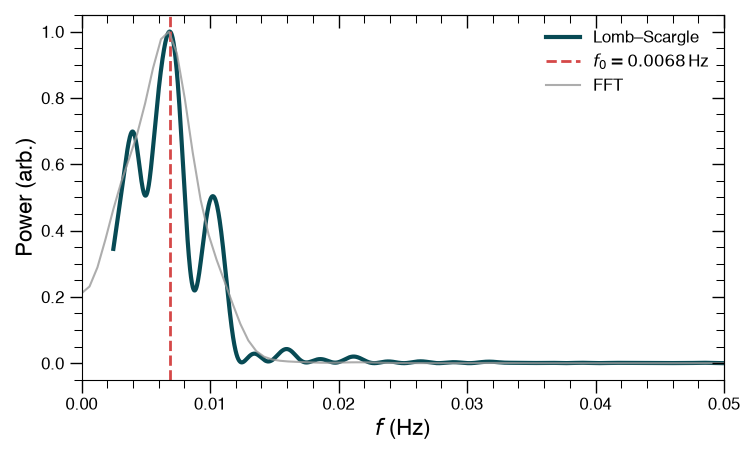

Lomb–Scargle peak = 0.0068 Hz
FFT peak          = 0.0064 Hz


In [14]:
from scipy.signal import lombscargle

# Lomb–Scargle periodogram of the residual (handles uneven τ sampling)
# Uses tau_trim, resid_trim from the FFT/residual cell above
y = detrend(np.asarray(resid_trim, dtype=float))
t = np.asarray(tau_trim, dtype=float)

# Angular frequencies (rad/s). Match the FFT frequency range for comparison.
f_max = max(5 * freqs[peak_idx], 0.05)
f_hz = np.linspace(1 / (t.max() - t.min()), f_max, 2000)
w = 2 * np.pi * f_hz

pgram = lombscargle(t, y, w, normalize=True)
peak_ls = np.argmax(pgram)

fig, ax = plt.subplots(figsize=(7.55, 4.55))
ax.plot(f_hz, pgram / pgram[peak_ls], color=freq_color, lw=3, label="Lomb–Scargle")
ax.axvline(f_hz[peak_ls], color=fit_color, ls="--", lw=2,
           label=fr"$f_0={f_hz[peak_ls]:.4f}\,$Hz")
ax.plot(freqs, power_no_dc / power_no_dc[peak_idx], color="0.6", lw=1.5, alpha=0.8, label="FFT")
ax.set_xlabel(r"$f$ (Hz)", fontsize=ax_label_font)
ax.set_ylabel(r"Power (arb.)", fontsize=ax_label_font)
ax.set_xlim(0, f_max)
ax.legend(frameon=False, fontsize=legend_ax_font)
asymmetric_ticks(ax, major_len=major_tick_length, minor_len=minor_tick_length,
                 major_w=major_tick_width, minor_w=minor_tick_width, labelsize=legend_ax_font)
plt.tight_layout()
plt.show()

print(f"Lomb–Scargle peak = {f_hz[peak_ls]:.4f} Hz")
print(f"FFT peak          = {popt_fft[1]:.4f} Hz")


(200.0, 1598.0)

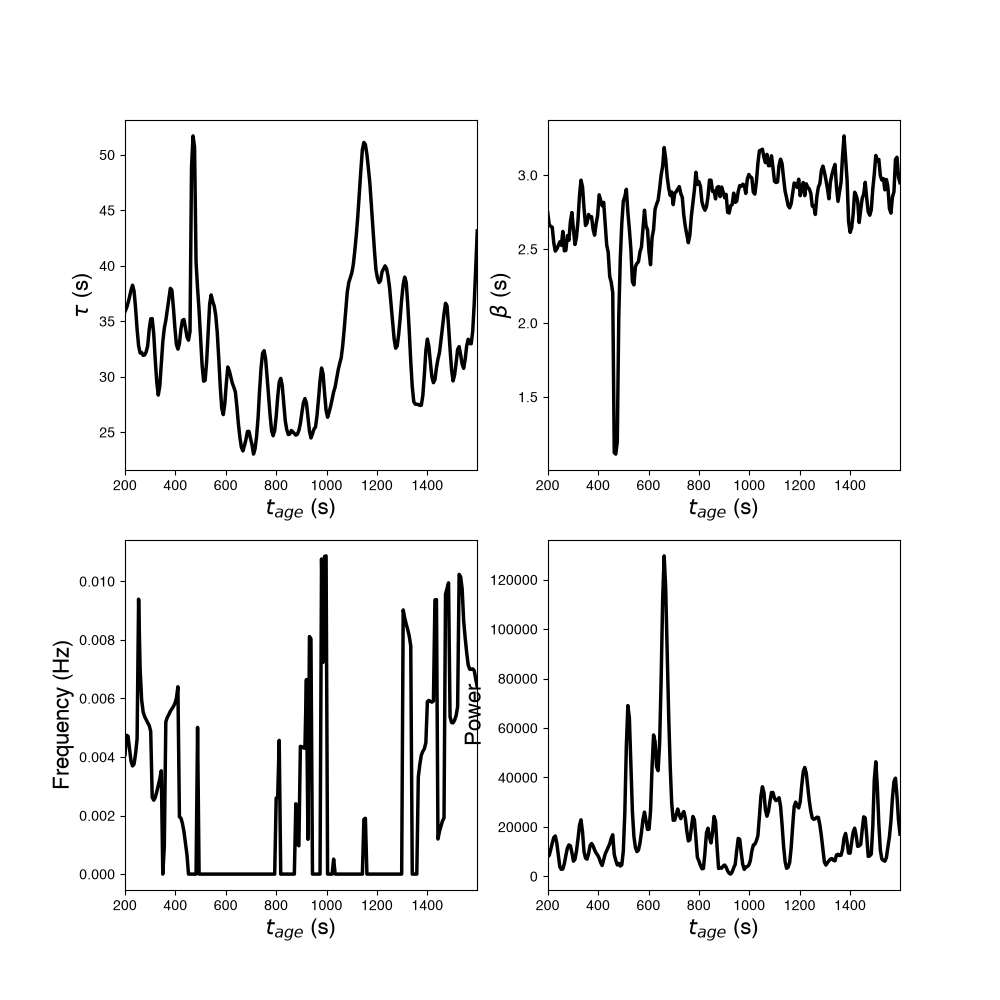

In [15]:


fig,ax = plt.subplots(2,2,figsize=(10,10))

ax[0,0].plot(t_age,taus,"k-",lw=2.5)
ax[0,0].set_xlabel(r"$t_{age}$ (s)",fontsize=ax_label_font)
ax[0,0].set_ylabel(r"$\tau$ (s)",fontsize=ax_label_font)

ax[0,0].set_xlim(t_age[0],t_age[-1])
#ax[0,0].set_ylim(10,40)

ax[0,1].plot(t_age,betas,"k-",lw=2.5)
ax[0,1].set_xlabel(r"$t_{age}$ (s)",fontsize=ax_label_font)
ax[0,1].set_ylabel(r"$\beta$ (s)",fontsize=ax_label_font)

ax[0,1].set_xlim(t_age[0],t_age[-1])
#ax[0,1].set_ylim(0,5)

ax[1,0].plot(t_age,max_freqs,"k-",lw=2.5)
ax[1,0].set_xlabel(r"$t_{age}$ (s)",fontsize=ax_label_font)
ax[1,0].set_ylabel(r"Frequency (Hz)",fontsize=ax_label_font)

ax[1,0].set_xlim(t_age[0],t_age[-1])
#ax[1,0].set_ylim(0,3)

ax[1,1].plot(t_age,max_powers,"k-",lw=2.5)
ax[1,1].set_xlabel(r"$t_{age}$ (s)",fontsize=ax_label_font)
ax[1,1].set_ylabel(r"Power",fontsize=ax_label_font)

ax[1,1].set_xlim(t_age[0],t_age[-1])
#ax[1,1].set_ylim(0,500)
